In [1]:
# notebook 08, regression: how far a routine bends, and whether a day is an emergency day. Kernel: Python (yjmob)
# Linear regression asks how much of a strange day an agent should believe: the same first emergency days, the same people, against two
# ordinary weeks. Logistic regression goes back to the Naive Bayes task (is this day from the emergency?) with the same days and people.
# It reads the tables of notebook 04, and for the logistic part rebuilds the half-hour states with breaks.py; a few minutes on 8 CPU cores
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT, REPO = Path("/projects/ancz7294/yjmob"), Path("/projects/ancz7294/agent-reliability-under-disruption")
PROC, CODE = ROOT / "data/processed", ROOT / "code"
FIG, SAMPLE, LOGS = REPO / "site/src/assets/figures", REPO / "data/samples", REPO / "logs"
sys.path.insert(0, str(CODE))
SEED = 20260917
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "font.family": "sans-serif", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
def save(fig, name): fig.savefig(FIG / f"{name}.png"); plt.show(); plt.close(fig)

def table_png(df, name, title, width=11, mono=(), widths=None):
    fig, ax = plt.subplots(figsize=(width, 0.3 * (len(df) + 1))); fig.subplots_adjust(0, 0, 1, 1); ax.axis("off"); ax.grid(False)
    w = np.asarray(widths if widths is not None else [1.0] * df.shape[1], float); w = w / w.sum()
    tb = ax.table(cellText=df.astype(str).values, colLabels=list(df.columns), cellLoc="left", colLoc="left", colWidths=list(w), bbox=[0, 0, 1, 1])
    tb.auto_set_font_size(False); tb.set_fontsize(8.5)
    for (r, c), cell in tb.get_celld().items():
        cell.set_edgecolor("#e1e0d9"); cell.PAD = 0.08 / (w[c] * width)
        if r == 0: cell.set_facecolor("#e8f0fb"); cell.set_text_props(weight="bold")
        elif df.columns[c] in mono: cell.set_text_props(family="monospace")
    ax.set_title(title, loc="left", fontweight="bold", fontsize=11, pad=8); save(fig, name)

ORDER = ["far roamers", "mid-range movers", "regular commuters", "local regulars", "weekend movers", "homebodies"]
COL = dict(zip(ORDER, [C[0], C[6], C[2], C[3], C[4], C[1]]))
days = pd.read_parquet(PROC / "day_table.parquet").set_index("d").sort_index()
kinds = pd.read_parquet(PROC / "person_kinds.parquet")
lab = pd.read_parquet(PROC / "person_breaks.parquet")                       # who broke (notebook 04), 23,904 people
wb = pd.read_parquet(PROC / "who_breaks_table.parquet")                    # their 34 features from days 0-44
sh = pd.read_parquet(PROC / "person_day_shares.parquet")                   # per person and day: seen half hours, at home, at the daytime place
rest_day = (~days.workday).to_numpy()
print(f"{len(kinds):,} people with a kind | {len(lab):,} with a who-broke label | person-days {len(sh):,}")
print("day types:", pd.Series(np.where(rest_day, "rest", "work")).groupby([pd.cut(np.arange(75), [-1, 14, 29, 44, 51, 59, 66, 74])]).value_counts().unstack().to_string())

24,514 people with a kind | 23,904 with a who-broke label | person-days 1,838,550
day types:           rest  work
(-1, 14]     7     8
(14, 29]     5    10
(29, 44]     5    10
(44, 51]     3     4
(51, 59]     2     6
(59, 66]     2     5
(66, 74]     3     5


/tmp/ipykernel_560832/2332961919.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print("day types:", pd.Series(np.where(rest_day, "rest", "work")).groupby([pd.cut(np.arange(75), [-1, 14, 29, 44, 51, 59, 66, 74])]).value_counts().unstack().to_string())


In [2]:
# what a person does on a day: of the half hours they are seen, the share away from home (00:00 left out, at least 4 seen half hours).
# Two arms with the same shape. Emergency: habits from days 15-59, the first k emergency days from day 60, the second emergency week 67-74.
# Ordinary weeks (placebo): habits from 0-44, the first k days from 45, the week 52-59. Same 45-day habit, same 7-day gap to the week
sh["away"] = sh.seen - sh.home; sh["rest"] = rest_day[sh.d]
ok = sh[sh.seen >= 4]
A = ok.pivot(index="uid", columns="d", values="away").reindex(columns=range(75))
N = ok.pivot(index="uid", columns="d", values="seen").reindex(columns=range(75))
people = lab.index.intersection(A.index)
A, N = A.loc[people], N.loc[people]
ARMS = {"ordinary": dict(habit=range(0, 45), fresh=45, week=range(52, 60)), "emergency": dict(habit=range(15, 60), fresh=60, week=range(67, 75))}
KS = [0, 1, 2, 3, 5, 7]

def habit_share(hd, wd):
    """the person's share of the day away from home over the habit days, kept apart for workdays and rest days, then mixed in the
    proportion of workdays and rest days of the days it should describe (a person with no rest day in the habit falls back to all days)"""
    hd = np.asarray(hd); out = {}
    for r in (False, True):
        c = hd[rest_day[hd] == r]; out[r] = A[c].sum(axis=1) / N[c].sum(axis=1)
    allh = A[hd].sum(axis=1) / N[hd].sum(axis=1)
    wr = rest_day[np.asarray(wd)].mean()
    return (1 - wr) * out[False].fillna(allh) + wr * out[True].fillna(allh), out, allh

def arm_table(arm):
    a = ARMS[arm]; wk = list(a["week"])
    H, by_type, allh = habit_share(a["habit"], wk)
    t = pd.DataFrame({"habit": H, "week": A[wk].sum(axis=1) / N[wk].sum(axis=1), "week_days": N[wk].notna().sum(axis=1)})
    for k in KS[1:]:
        fd = np.arange(a["fresh"], a["fresh"] + k)
        exp_ = sum(by_type[bool(rest_day[d])].fillna(allh) * N[d].fillna(0) for d in fd)          # what the habit expected on those days
        n_ = N[fd].sum(axis=1, min_count=1)
        t[f"fresh_{k}"] = ((A[fd].sum(axis=1, min_count=1) - exp_) / n_).fillna(0.0)    # how far the fresh days sat from the habit
        t[f"fresh_share_{k}"] = (A[fd].sum(axis=1, min_count=1) / n_)                   # the fresh days on their own
        t[f"seen_days_{k}"] = N[fd].notna().sum(axis=1)
    return t[t.week_days >= 3].dropna(subset=["habit", "week"])

T = {arm: arm_table(arm).join(lab[["split", "kind", "broke"]]) for arm in ARMS}
both = T["ordinary"].index.intersection(T["emergency"].index)
T = {arm: t.loc[both] for arm, t in T.items()}
print(f"people with a readable habit and at least 3 readable days in both weeks: {len(both):,} of {len(people):,}")
for arm, t in T.items():
    print(f"{arm:9s} habit {t.habit.mean():.3f} | week {t.week.mean():.3f} | week minus habit {(t.week - t.habit).mean():+.3f} | "
          f"sd of fresh_1 {t.fresh_1.std():.3f} | no readable fresh day among the first 1/3: {(t.seen_days_1 == 0).mean():.3f} / {(t.seen_days_3 == 0).mean():.3f}")
print(T["emergency"].groupby("kind")[["habit", "week"]].mean().reindex(ORDER).assign(change=lambda d: d.week - d.habit).round(3).to_string())

people with a readable habit and at least 3 readable days in both weeks: 23,476 of 23,904
ordinary  habit 0.684 | week 0.698 | week minus habit +0.014 | sd of fresh_1 0.156 | no readable fresh day among the first 1/3: 0.070 / 0.029
emergency habit 0.679 | week 0.690 | week minus habit +0.011 | sd of fresh_1 0.203 | no readable fresh day among the first 1/3: 0.042 / 0.006
                   habit   week  change
kind                                   
far roamers        0.870  0.871   0.001
mid-range movers   0.750  0.752   0.002
regular commuters  0.789  0.773  -0.016
local regulars     0.492  0.536   0.044
weekend movers     0.491  0.516   0.024
homebodies         0.248  0.288   0.040


In [3]:
# labelled data for the linear regression: one row per person, the target is the share of the second emergency week spent away from home.
# Training people are the development people of Parts 2 and 3, test people the evaluation people; nobody is in both
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
# home_share is left out: it is the habit again (share of records at home, days 0-44), and two copies of one input split its weight
TRAITS = ["regularity", "commute_km", "rg_km", "records_per_day"] + [c for c in wb.columns if c.startswith("kind: ")]
for arm in T: T[arm] = T[arm].drop(columns=[c for c in TRAITS if c in T[arm]]).join(wb[TRAITS])
E, O = T["emergency"], T["ordinary"]
tr, te = (E.split == "dev").to_numpy(), (E.split == "eval").to_numpy()
print(f"training {tr.sum():,} people | test {te.sum():,} | overlap {len(set(E.index[tr]) & set(E.index[te]))}")
SETS = {"habit only": ["habit"], "habit + first 3 days": ["habit", "fresh_3"],
        "habit + first 3 days + traits": ["habit", "fresh_3"] + TRAITS,
        "the same + days x regularity": ["habit", "fresh_3", "fresh_x_reg"] + TRAITS}
for t in T.values(): t["fresh_x_reg"] = t.fresh_3 * t.regularity
cv = KFold(5, shuffle=True, random_state=SEED)
rows_cv = []
for nm, cols in SETS.items():
    for a in [0.01, 1, 10, 100, 1000]:
        s = -cross_val_score(make_pipeline(StandardScaler(), Ridge(alpha=a)), E.loc[tr, cols], E.week[tr], cv=cv, scoring="neg_root_mean_squared_error")
        rows_cv.append((nm, a, s.mean() * 100, s.std() * 100))
cvt = pd.DataFrame(rows_cv, columns=["features", "ridge_alpha", "cv_rmse_pp", "sd"])
print(cvt.pivot(index="features", columns="ridge_alpha", values="cv_rmse_pp").reindex(list(SETS)).round(3).to_string())
best = cvt.loc[cvt.cv_rmse_pp.idxmin()]
gain = cvt[cvt.features == "habit + first 3 days"].cv_rmse_pp.min() - best.cv_rmse_pp
print(f"lowest cross-validated error: {best.features}, alpha {best.ridge_alpha}, {best.cv_rmse_pp:.3f} pp; "
      f"traits and the interaction take off another {gain:.3f} pp")

training 16,463 people | test 7,013 | overlap 0
ridge_alpha                    0.01     1.00     10.00    100.00   1000.00
features                                                                  
habit only                      15.611   15.611   15.611   15.611   15.669
habit + first 3 days            10.601   10.601   10.601   10.603   10.758
habit + first 3 days + traits   10.433   10.433   10.433   10.437   10.659
the same + days x regularity    10.435   10.435   10.435   10.440   10.694
lowest cross-validated error: habit + first 3 days + traits, alpha 1.0, 10.433 pp; traits and the interaction take off another 0.168 pp


model: habit + first 3 days + traits
                                               RMSE (pp)  MAE (pp)     R2
ordinary week, habit alone                         8.922     6.202  0.854
emergency week, habit alone                       15.953    11.226  0.591
emergency week, habit + first 3 days + traits     10.644     7.748  0.818
weights in plain units: {'habit': 0.9017, 'fresh_3': 0.6765, 'regularity': -0.0179, 'commute_km': 0.0004, 'rg_km': -0.0, 'records_per_day': 0.0017, 'kind: far roamers': 0.014, 'kind: mid-range movers': 0.0081, 'kind: regular commuters': 0.0161, 'kind: local regulars': -0.004, 'kind: weekend movers': -0.0532, 'kind: homebodies': -0.0374}
10 points more time away from home in a usual fortnight -> 9.0 points in the second week; first three days 10 points further from home than the habit expected -> 6.8 points more in the second week, other things equal
the two-input model alone: week = 0.030 + 0.969 x habit + 0.675 x (first three days minus habit)


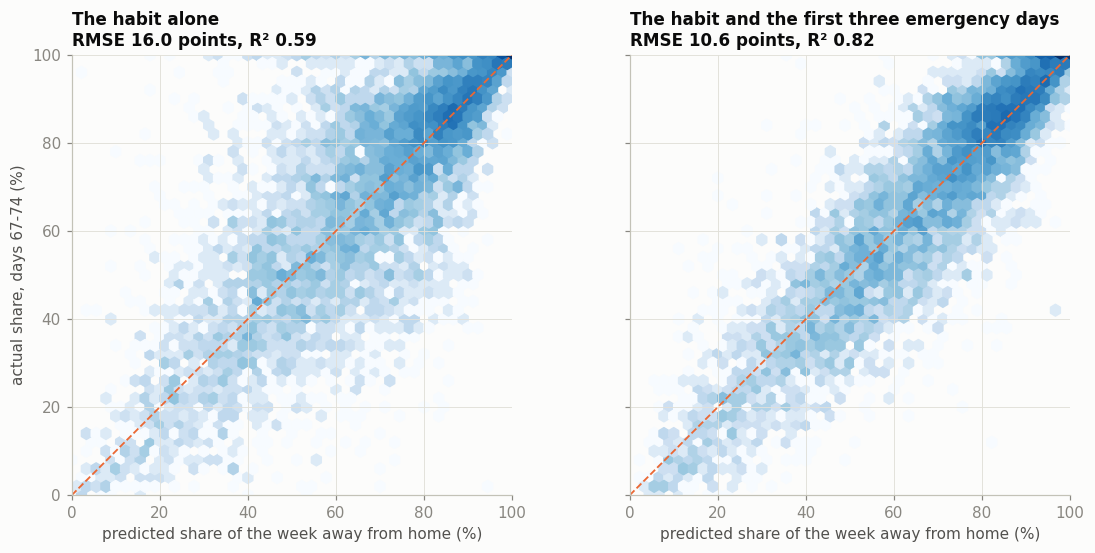

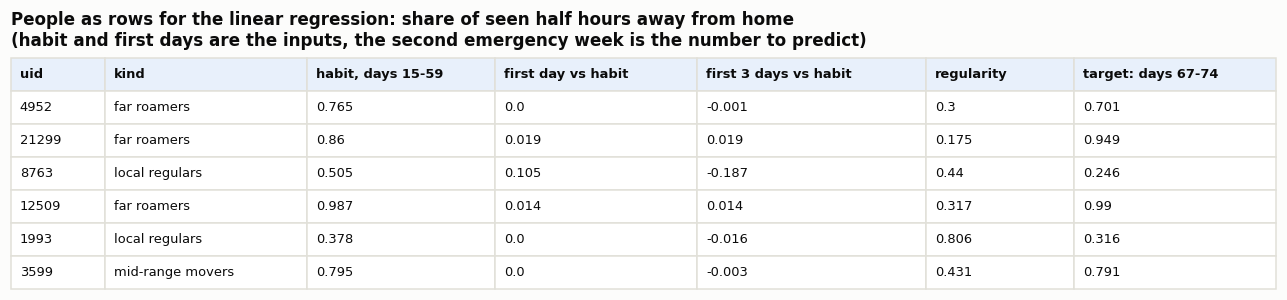

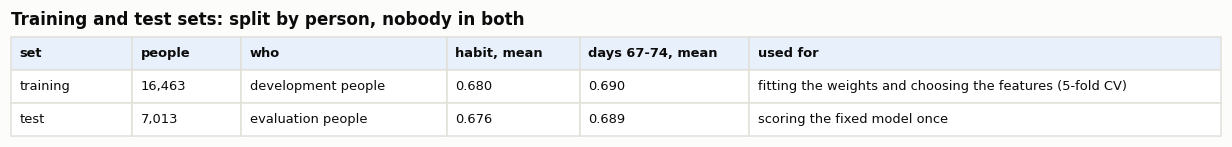

In [4]:
# the chosen settings are fixed, then the model is scored once on the test people. FINAL = the features cross-validation chose, unless the
# extra features buy less than 0.1 pp, in which case the two-feature model wins because every weight in it can be read
FINAL = best.features if gain >= 0.1 else "habit + first 3 days"
cols = SETS[FINAL]
m3 = make_pipeline(StandardScaler(), Ridge(alpha=best.ridge_alpha if FINAL == best.features else 0.01)).fit(E.loc[tr, cols], E.week[tr])
p_hab = E.habit[te]; p_mix = m3.predict(E.loc[te, cols]); y_te = E.week[te]
def scores(y, p): return {"RMSE (pp)": mean_squared_error(y, p) ** 0.5 * 100, "MAE (pp)": mean_absolute_error(y, p) * 100, "R2": r2_score(y, p)}
o_te = (O.split == "eval").to_numpy()
res = pd.DataFrame({"ordinary week, habit alone": scores(O.week[o_te], O.habit[o_te]),
                    "emergency week, habit alone": scores(y_te, p_hab), f"emergency week, {FINAL}": scores(y_te, p_mix)}).T
print("model:", FINAL); print(res.round(3).to_string())
sc, rg = m3.named_steps["standardscaler"], m3.named_steps["ridge"]
coef = pd.Series(rg.coef_ / sc.scale_, index=cols)                      # back in plain units: per point of share, per km, per 0/1
print("weights in plain units:", coef.round(4).to_dict())
print(f"10 points more time away from home in a usual fortnight -> {coef.habit * 10:.1f} points in the second week; first three days 10 points "
      f"further from home than the habit expected -> {coef.fresh_3 * 10:.1f} points more in the second week, other things equal")
two = LinearRegression().fit(E.loc[tr, ["habit", "fresh_3"]], E.week[tr])
print(f"the two-input model alone: week = {two.intercept_:.3f} + {two.coef_[0]:.3f} x habit + {two.coef_[1]:.3f} x (first three days minus habit)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True, sharey=True)
for ax, (p, ttl) in zip(axes, [(p_hab, "The habit alone"), (p_mix, "The habit and the first three emergency days")]):
    ax.hexbin(p * 100, y_te * 100, gridsize=45, cmap="Blues", mincnt=1, bins="log", extent=(0, 100, 0, 100))
    ax.plot([0, 100], [0, 100], color=C[1], lw=1.2, ls="--")
    s = scores(y_te, p); ax.set_title(f"{ttl}\nRMSE {s['RMSE (pp)']:.1f} points, R² {s['R2']:.2f}", fontsize=11)
    ax.set(xlabel="predicted share of the week away from home (%)", xlim=(0, 100), ylim=(0, 100)); ax.set_aspect("equal")
axes[0].set_ylabel("actual share, days 67-74 (%)")
save(fig, "f53_predicted_vs_actual")

# images for the site: the regression table and the split
show = E.loc[tr].sample(6, random_state=SEED)
t19 = pd.DataFrame({"uid": show.index, "kind": show.kind.to_numpy(), "habit, days 15-59": show.habit.round(3).to_numpy(),
                    "first day vs habit": show.fresh_1.round(3).to_numpy(), "first 3 days vs habit": show.fresh_3.round(3).to_numpy(),
                    "regularity": show.regularity.round(3).to_numpy(), "target: days 67-74": show.week.round(3).to_numpy()})
table_png(t19, "t19_regression_people", "People as rows for the linear regression: share of seen half hours away from home\n"
          "(habit and first days are the inputs, the second emergency week is the number to predict)", 11.5, widths=[0.07, 0.15, 0.14, 0.15, 0.17, 0.11, 0.15])
t20 = pd.DataFrame({"set": ["training", "test"], "people": [f"{tr.sum():,}", f"{te.sum():,}"], "who": ["development people", "evaluation people"],
                    "habit, mean": [f"{E.habit[tr].mean():.3f}", f"{E.habit[te].mean():.3f}"], "days 67-74, mean": [f"{E.week[tr].mean():.3f}", f"{E.week[te].mean():.3f}"],
                    "used for": ["fitting the weights and choosing the features (5-fold CV)", "scoring the fixed model once"]})
table_png(t20, "t20_regression_split", "Training and test sets: split by person, nobody in both", 11, widths=[0.1, 0.09, 0.17, 0.11, 0.14, 0.39])

   frozen habit  fresh days only  mix tuned in ordinary weeks  mix fitted in the emergency  ordinary week, mix
k                                                                                                             
0         15.95            15.95                        15.78                        15.65                8.80
1         15.95            16.51                        14.57                        12.78                8.66
2         15.95            13.48                        13.66                        11.61                8.51
3         15.95            11.90                        12.76                        10.80                8.39
5         15.95            10.27                        11.91                         9.75                8.25
7         15.95             8.88                        10.64                         8.93                8.03
ordinary-week error of the habit: 8.80 pp; the emergency mix gets within 10% of it after 7 fresh days
         a

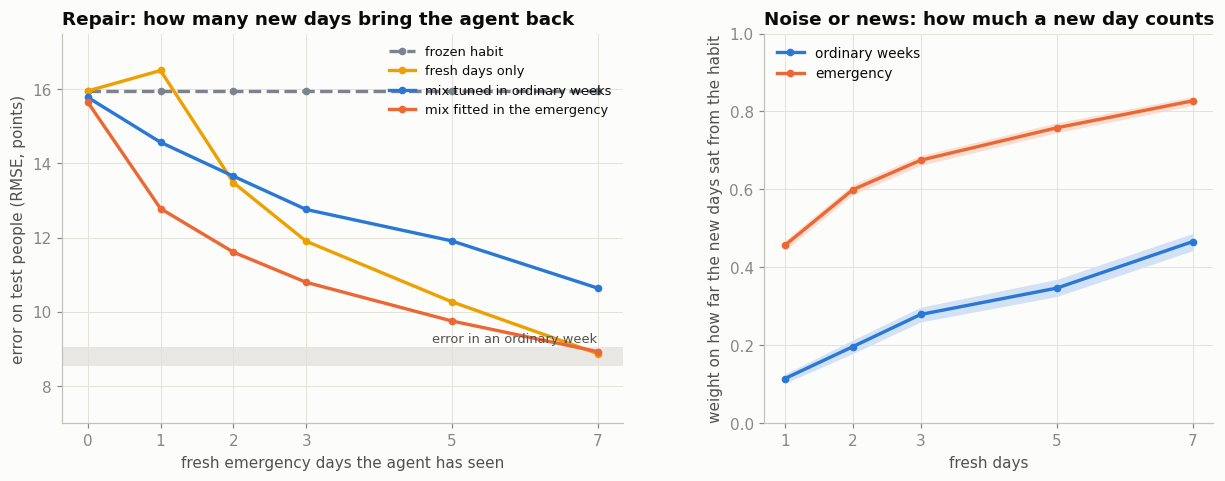

                   err_ord  err_habit  err_3  left_after_3
kind                                                      
far roamers           5.39      10.18   7.35          0.41
mid-range movers      8.78      15.10  10.64          0.29
regular commuters     7.85      14.91   9.95          0.30
local regulars       11.25      20.11  12.91          0.19
weekend movers       12.05      20.49  14.59          0.30
homebodies           10.45      18.98  12.23          0.21
               err_ord  err_habit  err_3  left_after_3
broke                                                 
routine broke     8.79      23.97  13.33          0.30
routine held      8.95      13.42  10.12          0.26


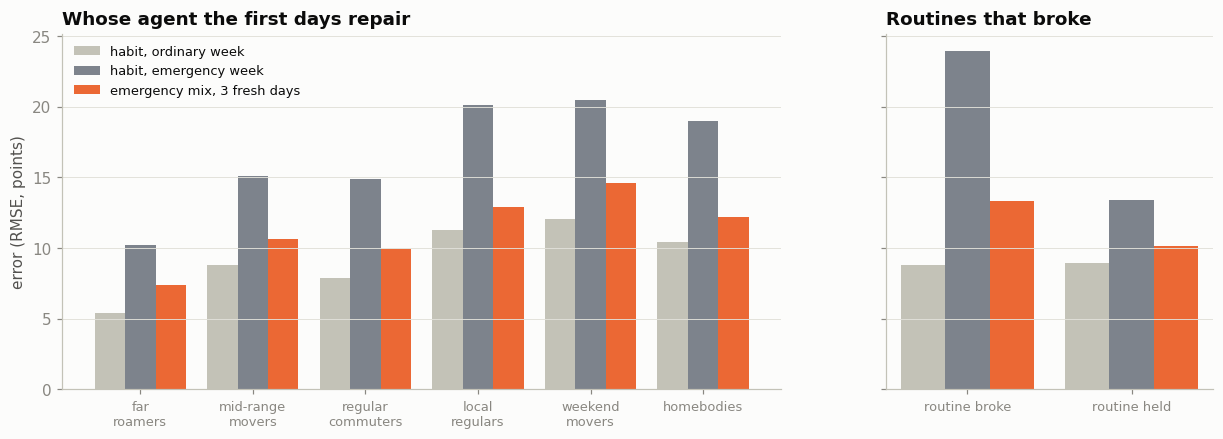

In [5]:
# the repair curve: how much each number of fresh days brings back, for four ways an agent can use them, scored on the test people.
# frozen habit = never look at the new days; fresh days only = forget the habit; the mix tuned in ordinary weeks = the weights an agent
# would carry over from normal times; the mix fitted in the emergency = the weights this emergency calls for (fitted on training people)
def mix(t, k, rows):
    if k == 0: return LinearRegression().fit(t.loc[rows, ["habit"]], t.week[rows])
    return LinearRegression().fit(t.loc[rows, ["habit", f"fresh_{k}"]], t.week[rows])
def predict(m, t, k, rows): return m.predict(t.loc[rows, ["habit"] if k == 0 else ["habit", f"fresh_{k}"]])
o_tr = (O.split == "dev").to_numpy()
rc = []
for k in KS:
    rmse = lambda p, y=y_te: mean_squared_error(y, p) ** 0.5 * 100
    fresh_only = E.loc[te, f"fresh_share_{k}"].fillna(E.habit[te]) if k else E.habit[te]
    rc.append({"k": k, "frozen habit": rmse(E.habit[te]), "fresh days only": rmse(fresh_only),
               "mix tuned in ordinary weeks": rmse(predict(mix(O, k, o_tr), E, k, te)),
               "mix fitted in the emergency": rmse(predict(mix(E, k, tr), E, k, te)),
               "ordinary week, mix": mean_squared_error(O.week[o_te], predict(mix(O, k, o_tr), O, k, o_te)) ** 0.5 * 100})
rc = pd.DataFrame(rc).set_index("k"); print(rc.round(2).to_string())
lvl = rc.loc[0, "ordinary week, mix"]
print(f"ordinary-week error of the habit: {lvl:.2f} pp; the emergency mix gets within 10% of it after "
      f"{next((k for k in KS if rc.loc[k, 'mix fitted in the emergency'] <= 1.1 * lvl), None)} fresh days")

# noise or news: the weight on the fresh days in each arm, with 95% intervals from 500 bootstrap samples of training people
B = 500; rng = np.random.default_rng(SEED); w_rows = []
for arm, t in T.items():
    trm = (t.split == "dev").to_numpy(); tt = t[trm]
    for k in KS[1:]:
        Xk = np.c_[np.ones(len(tt)), tt.habit, tt[f"fresh_{k}"]]; yk = tt.week.to_numpy()
        b0 = np.linalg.lstsq(Xk, yk, rcond=None)[0]
        bs = np.array([np.linalg.lstsq(Xk[r], yk[r], rcond=None)[0] for r in (rng.integers(0, len(tt), len(tt)) for _ in range(B))])
        w_rows.append((arm, k, b0[2], *np.percentile(bs[:, 2], [2.5, 97.5]), b0[1], *np.percentile(bs[:, 1], [2.5, 97.5])))
W = pd.DataFrame(w_rows, columns=["arm", "k", "w_fresh", "lo", "hi", "w_habit", "h_lo", "h_hi"])
print(W.round(3).to_string())
for arm in ARMS:
    w = W[W.arm == arm].set_index("k")
    print(arm, "mix as weights on habit and on the new days:", {k: (round(w.w_habit[k] - w.w_fresh[k], 3), round(w.w_fresh[k], 3)) for k in w.index})

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1.25, 1], "wspace": 0.28})
ax = axes[0]
ax.axhspan(lvl * 0.97, lvl * 1.03, color="#c3c2b7", alpha=0.35, lw=0)
ax.text(7, lvl * 1.035, "error in an ordinary week", ha="right", va="bottom", fontsize=8.5, color="#52514e")
for nm, c_, ls in [("frozen habit", "#7d838c", "--"), ("fresh days only", C[3], "-"), ("mix tuned in ordinary weeks", C[0], "-"), ("mix fitted in the emergency", C[1], "-")]:
    ax.plot(rc.index, rc[nm], color=c_, lw=2.2, ls=ls, marker="o", ms=4, label=nm)
ax.set(xlabel="fresh emergency days the agent has seen", ylabel="error on test people (RMSE, points)", xticks=KS, ylim=(7, 17.5),
       title="Repair: how many new days bring the agent back")
ax.legend(frameon=False, fontsize=8.5, loc="upper right")
ax = axes[1]
for arm, c_ in [("ordinary", C[0]), ("emergency", C[1])]:
    w = W[W.arm == arm]; ax.plot(w.k, w.w_fresh, color=c_, lw=2.2, marker="o", ms=4, label="ordinary weeks" if arm == "ordinary" else "emergency")
    ax.fill_between(w.k, w.lo, w.hi, color=c_, alpha=0.2, lw=0)
ax.set(xlabel="fresh days", ylabel="weight on how far the new days sat from the habit", ylim=(0, 1), xticks=KS[1:], title="Noise or news: how much a new day counts")
ax.legend(frameon=False, fontsize=9, loc="upper left")
save(fig, "f54_repair_curve")

# who needs more days: error of the habit and of the emergency mix after 3 days, by kind of mover and for people whose routine broke
m_e3 = mix(E, 3, tr); Et = E[te].copy()
Et["err_habit"] = (Et.week - Et.habit) ** 2; Et["err_3"] = (Et.week - predict(m_e3, E, 3, te)) ** 2
Et["err_ord"] = (O.week[o_te] - O.habit[o_te]).reindex(Et.index) ** 2
g = lambda by: Et.groupby(by)[["err_ord", "err_habit", "err_3"]].mean().pow(0.5).mul(100)
bk = g("kind").reindex(ORDER); bb = g(Et.broke.map({True: "routine broke", False: "routine held"}))
bk["left_after_3"] = (bk.err_3 - bk.err_ord) / (bk.err_habit - bk.err_ord); bb["left_after_3"] = (bb.err_3 - bb.err_ord) / (bb.err_habit - bb.err_ord)
print(bk.round(2).to_string()); print(bb.round(2).to_string())
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2), sharey=True, gridspec_kw={"width_ratios": [2.2, 1]})
for ax, tab, lbls in [(axes[0], bk, [k.replace(" ", "\n", 1) for k in ORDER]), (axes[1], bb, list(bb.index))]:
    x = np.arange(len(tab)); wdt = 0.27
    ax.bar(x - wdt, tab.err_ord, wdt, color="#c3c2b7", label="habit, ordinary week")
    ax.bar(x, tab.err_habit, wdt, color="#7d838c", label="habit, emergency week")
    ax.bar(x + wdt, tab.err_3, wdt, color=C[1], label="emergency mix, 3 fresh days")
    ax.set_xticks(x); ax.set_xticklabels(lbls, fontsize=8.5); ax.xaxis.grid(False)
axes[0].set(ylabel="error (RMSE, points)", title="Whose agent the first days repair"); axes[1].set_title("Routines that broke")
axes[0].legend(frameon=False, fontsize=8.5, loc="upper left")
save(fig, "f55_repair_by_kind")

In [6]:
# logistic regression goes back to the Naive Bayes task: is a person-day from the ordinary fortnight (45-59) or the emergency (60-74)?
# The same readable days and the same people in training, validation and test, rebuilt exactly as in notebook 04
import importlib, breaks; importlib.reload(breaks)
from breaks import *
t0 = time.time()
an = pd.read_parquet(PROC / "yjmob_analysis.parquet", columns=["uid", "d", "t", "x", "y"])
anc = pd.read_parquet(PROC / "person_anchors.parquet")
uids = np.sort(kinds.index.to_numpy()); split = kinds.split.reindex(uids).to_numpy(); kind = kinds.kind.reindex(uids).to_numpy()
S = slot_states(an[an.uid.isin(uids)], anc, uids); del an
rows = day_rows(S, uids, np.arange(45, 75), rest_day)
rows["y"] = (rows.d >= 60).astype(int); rows["split"] = split[rows.i]; rows["kind"] = kind[rows.i]; rows["p"] = rows.i
rng = np.random.default_rng(SEED)
dev_people = np.unique(rows.uid[rows.split == "dev"])
val_people = rng.choice(dev_people, len(dev_people) // 5, replace=False)
train = rows[(rows.split == "dev") & ~rows.uid.isin(val_people)]; val = rows[rows.uid.isin(val_people)]; test = rows[rows.split == "eval"]
dev = rows[rows.split == "dev"]
print(f"half-hour states rebuilt in {time.time() - t0:.0f} s | train {len(train):,} days of {train.uid.nunique():,} people | "
      f"validation {len(val):,} of {val.uid.nunique():,} | test {len(test):,} of {test.uid.nunique():,} (notebook 04: 379,586 / 94,965 / 202,744)")

# each person's own habits from days 0-44, pulled toward their kind of mover, as in notebook 04 (alpha 10, prior strength chosen by the data)
own = person_counts(S, np.arange(len(uids)), np.arange(0, 45), rest_day)
kind_base = {k: smooth(own[(kind == k) & (split == "dev")].sum(axis=0), 10.0) for k in ORDER}
prior_p = np.stack([kind_base[k] for k in kind])
m_p, _ = best_m(own[split == "dev"], prior_p[split == "dev"], [0.25, 0.5, 1, 2, 4, 8, 16, 32, 64])
base = shrink(own, prior_p, m_p); print("person-level prior strength:", m_p)

def unusual(rows):
    """for each half hour, how unusual the person's state was for them: surprise under their own habits, 0 when not seen"""
    k = S[rows.i.to_numpy(), rows.d.to_numpy()][:, SLOTS].astype("int16") - 1
    rest = rows.rest.to_numpy().astype(int); p = rows.p.to_numpy(); out = np.zeros(k.shape, dtype="float32")
    for s in range(len(SLOTS)):
        m = k[:, s] >= 0
        out[m, s] = -np.log(base[p[m], rest[m], s, k[m, s]])
    return out
FEATS = {"the clock": lambda r: words(S, r), "the person": unusual, "both": lambda r: np.hstack([words(S, r), unusual(r)])}
XS = {nm: {part: f(r) for part, r in [("train", train), ("val", val), ("dev", dev), ("test", test)]} for nm, f in FEATS.items()}
print({nm: v["train"].shape[1] for nm, v in XS.items()}, "inputs per day")

half-hour states rebuilt in 3 s | train 379,586 days of 13,732 people | validation 94,965 of 3,432 | test 202,744 of 7,350 (notebook 04: 379,586 / 94,965 / 202,744)
person-level prior strength: 4.0
{'the clock': 282, 'the person': 47, 'both': 329} inputs per day


In [7]:
# the strength of the penalty (C, smaller = stronger) chosen on the validation people, by log loss as for the Naive Bayes smoothing
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, confusion_matrix
from joblib import Parallel, delayed
CS = [1e-6, 1e-5, 1e-4, 1e-3, 0.01, 0.1, 1]
def logit(c): return make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=3000))
def tune(nm, c):
    p = logit(c).fit(XS[nm]["train"], train.y).predict_proba(XS[nm]["val"])[:, 1]
    return nm, c, accuracy_score(val.y, p > 0.5), roc_auc_score(val.y, p), log_loss(val.y, p)
t0 = time.time()
tun = pd.DataFrame(Parallel(n_jobs=8)(delayed(tune)(nm, c) for nm in XS for c in CS), columns=["inputs", "C", "accuracy", "AUC", "log_loss"])
print(f"{len(tun)} fits in {time.time() - t0:.0f} s")
for v in ["accuracy", "AUC", "log_loss"]: print(tun.pivot(index="C", columns="inputs", values=v).round(4).to_string())
best_C = tun.loc[tun.groupby("inputs").log_loss.idxmin()].set_index("inputs").C
print("C with the lowest validation log loss:", best_C.to_dict())

21 fits in 11 s
inputs      both  the clock  the person
C                                      
0.000001  0.5706     0.5681      0.5068
0.000010  0.5899     0.5785      0.5162
0.000100  0.5891     0.5785      0.5181
0.001000  0.5895     0.5781      0.5181
0.010000  0.5894     0.5781      0.5181
0.100000  0.5894     0.5781      0.5181
1.000000  0.5894     0.5780      0.5181
inputs      both  the clock  the person
C                                      
0.000001  0.5959     0.5903      0.5265
0.000010  0.6156     0.5961      0.5274
0.000100  0.6203     0.5978      0.5279
0.001000  0.6206     0.5980      0.5279
0.010000  0.6207     0.5981      0.5279
0.100000  0.6207     0.5981      0.5279
1.000000  0.6207     0.5981      0.5279
inputs      both  the clock  the person
C                                      
0.000001  0.6855     0.6859      0.6927
0.000010  0.6732     0.6781      0.6921
0.000100  0.6691     0.6769      0.6920
0.001000  0.6689     0.6770      0.6920
0.010000  0.6690     0.6

                                           accuracy     AUC  log loss
Naive Bayes, multinomial (where and when)    0.5274  0.5384    0.7837
Naive Bayes, Bernoulli (when seen)           0.5745  0.5909    0.8423
Naive Bayes, where only (from scratch)       0.5305  0.5318    0.7661
logistic, the clock                          0.5822  0.6028    0.6752
logistic, the person                         0.5210  0.5280    0.6919
logistic, both                               0.5903  0.6214    0.6688
Naive Bayes, per person (empirical Bayes)    0.5398  0.5591       NaN
majority class: 0.5103


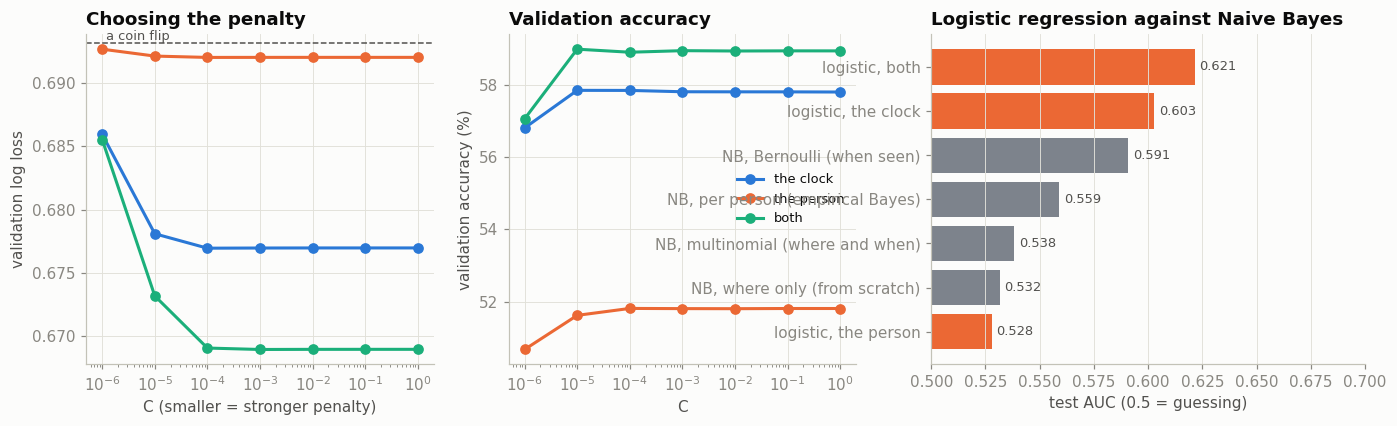

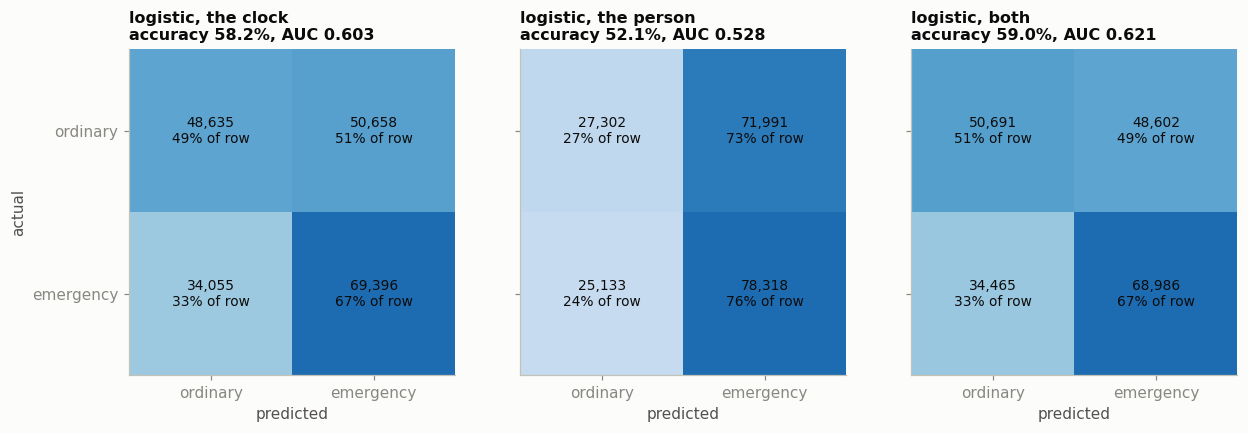

confusion counts (tn, fp, fn, tp): {'the clock': [48635, 50658, 34055, 69396], 'the person': [27302, 71991, 25133, 78318], 'both': [50691, 48602, 34465, 68986]}
workday, largest odds ratio for home against elsewhere: 1.070 at 19:30; smallest 0.918 at 08:30
odds ratio home vs elsewhere, workday: {'01:00': 0.985, '02:00': 0.969, '03:00': 1.009, '04:00': 1.0, '05:00': 0.989, '06:00': 0.989, '07:00': 0.934, '08:00': 0.932, '09:00': 0.986, '10:00': 0.978, '11:00': 0.997, '12:00': 1.004, '13:00': 0.996, '14:00': 1.023, '15:00': 0.963, '16:00': 0.997, '17:00': 1.006, '18:00': 1.027, '19:00': 1.03, '20:00': 1.041, '21:00': 1.059, '22:00': 1.002, '23:00': 0.942}
odds ratio daytime place vs elsewhere, workday: {'01:00': 1.033, '02:00': 1.059, '03:00': 1.193, '04:00': 1.005, '05:00': 1.079, '06:00': 0.96, '07:00': 1.002, '08:00': 0.957, '09:00': 0.952, '10:00': 0.961, '11:00': 0.959, '12:00': 0.898, '13:00': 0.953, '14:00': 0.952, '15:00': 0.963, '16:00': 0.974, '17:00': 0.994, '18:00': 0.959, '1

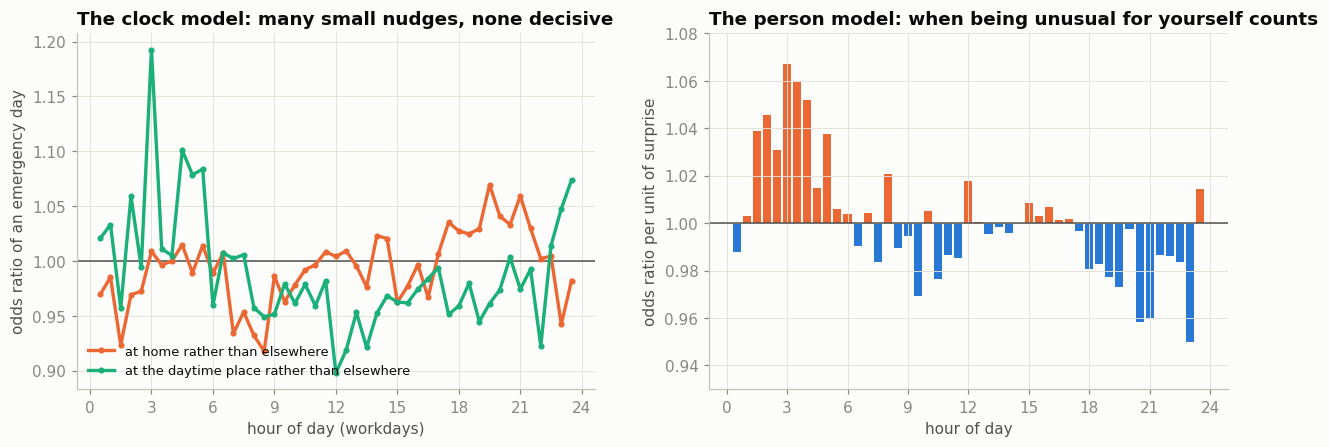

In [8]:
# final models on all development people with the chosen C, scored once on the test days, beside the Naive Bayes models of notebook 04
final = {nm: logit(best_C[nm]).fit(XS[nm]["dev"], dev.y) for nm in XS}
pt = {nm: m.predict_proba(XS[nm]["test"])[:, 1] for nm, m in final.items()}
nb = pd.read_csv(PROC / "nb_models_eval.csv", index_col=0); ebd = pd.read_csv(PROC / "nb_detectors_eval.csv")
cmp_ = pd.DataFrame({f"logistic, {nm}": {"accuracy": accuracy_score(test.y, p > 0.5), "AUC": roc_auc_score(test.y, p), "log loss": log_loss(test.y, p)}
                     for nm, p in pt.items()}).T
cmp_ = pd.concat([nb.rename(index=lambda s: f"Naive Bayes, {s}"), cmp_])
eb = ebd[(ebd.kind == "all") & (ebd.detector == "one per person")].iloc[0]
cmp_.loc["Naive Bayes, per person (empirical Bayes)"] = [eb.accuracy, eb.AUC, np.nan]
print(cmp_.round(4).to_string()); print(f"majority class: {max(test.y.mean(), 1 - test.y.mean()):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), gridspec_kw={"width_ratios": [1, 1, 1.25]})
for j, (nm, g_) in enumerate(tun.groupby("inputs", sort=False)):
    axes[0].plot(g_.C, g_.log_loss, marker="o", lw=2, color=C[j], label=nm); axes[1].plot(g_.C, g_.accuracy * 100, marker="o", lw=2, color=C[j], label=nm)
axes[0].axhline(np.log(2), color="#52514e", lw=1, ls="--"); axes[0].text(1e-6, np.log(2), " a coin flip", va="bottom", fontsize=8.5, color="#52514e")
axes[0].set(xscale="log", xlabel="C (smaller = stronger penalty)", ylabel="validation log loss", title="Choosing the penalty")
axes[1].set(xscale="log", xlabel="C", ylabel="validation accuracy (%)", title="Validation accuracy"); axes[1].legend(frameon=False, fontsize=8.5)
ax = axes[2]; order_ = cmp_.sort_values("AUC").index
cols_ = [C[1] if s.startswith("logistic") else "#7d838c" for s in order_]
ax.barh([s.replace("Naive Bayes, ", "NB, ").replace("logistic, ", "logistic, ") for s in order_], cmp_.loc[order_, "AUC"], color=cols_)
for i_, v in enumerate(cmp_.loc[order_, "AUC"]): ax.text(v + 0.002, i_, f"{v:.3f}", va="center", fontsize=8.5, color="#52514e")
ax.set(xlim=(0.5, max(0.7, cmp_.AUC.max() + 0.03)), xlabel="test AUC (0.5 = guessing)", title="Logistic regression against Naive Bayes"); ax.yaxis.grid(False)
save(fig, "f56_logistic_tuning_and_nb")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (nm, p) in zip(axes, pt.items()):
    cm = confusion_matrix(test.y, p > 0.5)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.3); ax.grid(False)
    for (r, c_), v in np.ndenumerate(cm): ax.text(c_, r, f"{v:,}\n{v / cm[r].sum():.0%} of row", ha="center", va="center", fontsize=9)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["ordinary", "emergency"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["ordinary", "emergency"])
    ax.set_xlabel("predicted"); ax.set_title(f"logistic, {nm}\naccuracy {accuracy_score(test.y, p > 0.5):.1%}, AUC {roc_auc_score(test.y, p):.3f}", fontsize=10.5)
axes[0].set_ylabel("actual")
for ax in axes[1:]: ax.set_yticklabels([])
save(fig, "f57_logistic_confusion")
print("confusion counts (tn, fp, fn, tp):", {nm: confusion_matrix(test.y, p > 0.5).ravel().tolist() for nm, p in pt.items()})

# what the weights say: the clock model in odds. For each half hour of a workday, how much being seen at home (or at the daytime place)
# rather than elsewhere multiplies the odds that the day is an emergency day; and per half hour, what one unit of 'unusual for this
# person' does to the odds in the person model
def raw_coef(m): return m.named_steps["logisticregression"].coef_[0] / m.named_steps["standardscaler"].scale_
wc = raw_coef(final["the clock"]).reshape(2, len(SLOTS), 3)          # day type x half hour x (home, daytime place, elsewhere)
wp = raw_coef(final["the person"])
hours = SLOTS / 2
or_home, or_place = np.exp(wc[0, :, 0] - wc[0, :, 2]), np.exp(wc[0, :, 1] - wc[0, :, 2])
j = int(np.argmax(or_home)); jp = int(np.argmax(np.exp(wp)))
hm = lambda h: f"{int(h):02d}:{int(round(60 * (h % 1))):02d}"
print(f"workday, largest odds ratio for home against elsewhere: {or_home[j]:.3f} at {hm(hours[j])}; smallest {or_home.min():.3f} at {hm(hours[int(np.argmin(or_home))])}")
print("odds ratio home vs elsewhere, workday:", {hm(h): round(float(v), 3) for h, v in zip(hours, or_home) if h % 1 == 0})
print("odds ratio daytime place vs elsewhere, workday:", {hm(h): round(float(v), 3) for h, v in zip(hours, or_place) if h % 1 == 0})
print("per-unit-surprise odds ratio by hour:", {hm(h): round(float(v), 3) for h, v in zip(hours, np.exp(wp)) if h % 1 == 0})
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2), gridspec_kw={"wspace": 0.22})
ax = axes[0]; ax.axhline(1, color="#52514e", lw=1)
ax.plot(hours, or_home, color=C[1], lw=2.2, marker="o", ms=3, label="at home rather than elsewhere")
ax.plot(hours, or_place, color=C[2], lw=2.2, marker="o", ms=3, label="at the daytime place rather than elsewhere")
ax.set(xlabel="hour of day (workdays)", ylabel="odds ratio of an emergency day", xticks=range(0, 25, 3), title="The clock model: many small nudges, none decisive")
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
ax = axes[1]; ax.axhline(1, color="#52514e", lw=1)
ax.bar(hours, np.exp(wp) - 1, width=0.4, bottom=1, color=[C[1] if v > 1 else C[0] for v in np.exp(wp)])
ax.set(xlabel="hour of day", ylabel="odds ratio per unit of surprise", xticks=range(0, 25, 3), ylim=(0.93, 1.08), title="The person model: when being unusual for yourself counts")
save(fig, "f58_odds_clock")

In [9]:
# outputs: a sample of the regression table for the site, and every number of this notebook in one log
cols_out = ["kind", "split", "broke", "habit", "fresh_1", "fresh_3", "fresh_7", "fresh_share_3", "week", "regularity", "commute_km", "records_per_day"]
E.sample(500, random_state=SEED)[cols_out].round(4).to_csv(SAMPLE / "regression_week_sample.csv")
pd.concat(T, names=["arm"]).to_parquet(PROC / "regression_people.parquet")              # read by notebook 09 (one day in)
log = {"people": {"rows": len(E), "train": int(tr.sum()), "test": int(te.sum())},
       "linear_cv_rmse_pp": cvt.pivot(index="features", columns="ridge_alpha", values="cv_rmse_pp").round(3).to_dict(),
       "linear_final": FINAL, "linear_test": res.round(4).to_dict(), "linear_weights_plain_units": coef.round(4).to_dict(),
       "two_input_model": {"intercept": round(float(two.intercept_), 4), "habit": round(float(two.coef_[0]), 4), "fresh_3": round(float(two.coef_[1]), 4)},
       "repair_rmse_pp": rc.round(3).to_dict(), "fresh_weights": W.round(4).to_dict(orient="records"),
       "repair_by_kind": bk.round(3).to_dict(), "repair_by_broke": bb.round(3).to_dict(),
       "logistic_validation": tun.round(4).to_dict(orient="records"), "logistic_best_C": best_C.to_dict(),
       "logistic_vs_nb_test": cmp_.round(4).to_dict(), "logistic_confusion_tn_fp_fn_tp": {nm: confusion_matrix(test.y, p > 0.5).ravel().tolist() for nm, p in pt.items()},
       "odds_home_vs_elsewhere_workday": {hm(h): round(float(v), 4) for h, v in zip(hours, or_home)},
       "odds_place_vs_elsewhere_workday": {hm(h): round(float(v), 4) for h, v in zip(hours, or_place)},
       "odds_per_unit_surprise": {hm(h): round(float(v), 4) for h, v in zip(hours, np.exp(wp))}}
(LOGS / "part4_regression_log.json").write_text(json.dumps(log, indent=2, default=str))
print(json.dumps({k: log[k] for k in ["people", "linear_final", "logistic_best_C"]}, default=str))
print(sorted(p.name for p in FIG.glob("[ft][5-6]*.png")) + sorted(p.name for p in FIG.glob("t[12][0-9]_*.png") if p.name >= "t19"))

{"people": {"rows": 23476, "train": 16463, "test": 7013}, "linear_final": "habit + first 3 days + traits", "logistic_best_C": {"both": 0.001, "the clock": 0.0001, "the person": 0.0001}}
['f50_independent_check.png', 'f51_triage.png', 'f52_llm_stand_ins.png', 'f53_predicted_vs_actual.png', 'f54_repair_curve.png', 'f55_repair_by_kind.png', 'f56_logistic_tuning_and_nb.png', 'f57_logistic_confusion.png', 'f58_odds_clock.png', 'f59_adaboost_rounds.png', 'f60_adaboost_confusion.png', 'f61_stumps_and_votes.png', 'f62_who_it_cannot_learn.png', 't19_regression_people.png', 't20_regression_split.png', 't21_onehot.png', 't22_adaboost_split.png', 't23_first_stumps.png']
